# Studi Komparatif Model Generatif (Fashion-MNIST)

## 1. Setup dan Seed

In [2]:
import os
import json
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, models
from sklearn.model_selection import StratifiedShuffleSplit

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

SEED = 42
BATCH_SIZE = 128
FORCE_RERUN = False

DATA_ROOT = "data"
RESULTS_DIR = "results"
FIGS_DIR = os.path.join(RESULTS_DIR, "figs")
WEIGHTS_DIR = os.path.join(RESULTS_DIR, "weights")
SPLITS_PATH = os.path.join(RESULTS_DIR, "splits.json")
RUNS_PATH = os.path.join(RESULTS_DIR, "runs.csv")
METRICS_PATH = os.path.join(RESULTS_DIR, "metrics.json")

for folder in (DATA_ROOT, FIGS_DIR, WEIGHTS_DIR):
    os.makedirs(folder, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

set_seed(SEED)
print(f"Working dir: {os.getcwd()}")
print(f"PyTorch: {torch.__version__} | Device: {device}")


Working dir: /home/cele/kuliah/semester-5/deep-learning/tugas-ae-gan
PyTorch: 2.5.1+cu121 | Device: cuda


## 2. Dataset dan Split 80/10/10


100%|██████████| 26.4M/26.4M [01:52<00:00, 235kB/s] 


Extracting data/FashionMNIST/raw/train-images-idx3-ubyte.gz to data/FashionMNIST/raw



100%|██████████| 29.5k/29.5k [00:00<00:00, 154kB/s]


Extracting data/FashionMNIST/raw/train-labels-idx1-ubyte.gz to data/FashionMNIST/raw



100%|██████████| 4.42M/4.42M [00:03<00:00, 1.19MB/s]


Extracting data/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to data/FashionMNIST/raw



100%|██████████| 5.15k/5.15k [00:00<00:00, 20.8MB/s]


Extracting data/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to data/FashionMNIST/raw

Total: 70000 | Train: 56000 | Val: 7000 | Test: 7000
Pixel range: 0.0 to 1.0


,train,val,test
T-shirt/top,5600,700,700
Trouser,5600,700,700
Pullover,5600,700,700
Dress,5600,700,700
Coat,5600,700,700
Sandal,5600,700,700
Shirt,5600,700,700
Sneaker,5600,700,700
Bag,5600,700,700
Ankle boot,5600,700,700


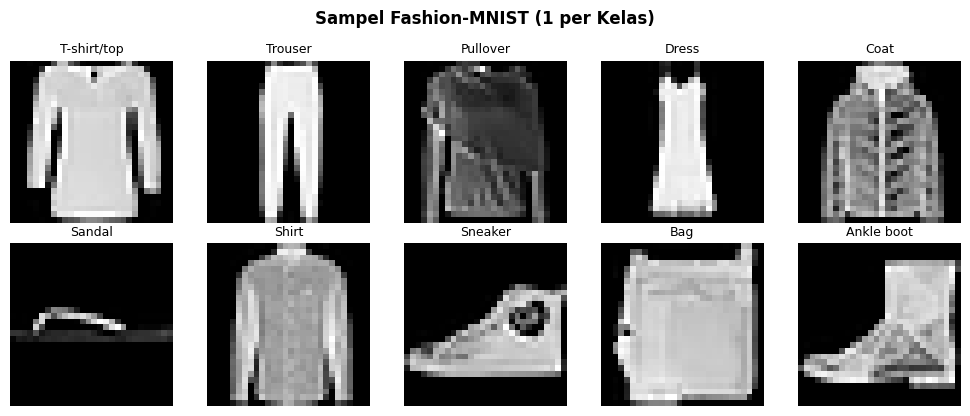

In [3]:
raw_train = datasets.FashionMNIST(root=DATA_ROOT, train=True, download=True)
raw_test = datasets.FashionMNIST(root=DATA_ROOT, train=False, download=True)

CLASS_NAMES = list(raw_train.classes)
all_images_u8 = torch.cat([raw_train.data, raw_test.data], dim=0)
all_targets = torch.cat([raw_train.targets, raw_test.targets], dim=0)
all_images = all_images_u8.float().unsqueeze(1) / 255.0

if os.path.exists(SPLITS_PATH):
    with open(SPLITS_PATH) as f:
        splits = json.load(f)
else:
    labels_np = all_targets.numpy()
    indices_np = np.arange(len(labels_np))
    train_idx, rest_idx = next(
        StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED).split(indices_np, labels_np)
    )
    rest_labels = labels_np[rest_idx]
    val_pos, test_pos = next(
        StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED).split(rest_idx, rest_labels)
    )
    val_idx, test_idx = rest_idx[val_pos], rest_idx[test_pos]

    assert not (set(train_idx) & set(val_idx))
    assert not (set(train_idx) & set(test_idx))
    assert not (set(val_idx) & set(test_idx))

    splits = {
        "classes": CLASS_NAMES,
        "train_indices": [int(i) for i in train_idx],
        "val_indices": [int(i) for i in val_idx],
        "test_indices": [int(i) for i in test_idx],
    }
    with open(SPLITS_PATH, "w") as f:
        json.dump(splits, f)

train_ds = TensorDataset(all_images[splits["train_indices"]], all_targets[splits["train_indices"]])
val_ds = TensorDataset(all_images[splits["val_indices"]], all_targets[splits["val_indices"]])
test_ds = TensorDataset(all_images[splits["test_indices"]], all_targets[splits["test_indices"]])

loader_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    generator=loader_gen, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=torch.cuda.is_available())

print(f"Total: {len(all_images)} | Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
print(f"Pixel range: {all_images.min().item():.1f} to {all_images.max().item():.1f}")

targets_np = all_targets.numpy()
dist_df = pd.DataFrame(
    {name: np.bincount(targets_np[splits[f"{name}_indices"]], minlength=len(CLASS_NAMES)) for name in ("train", "val", "test")},
    index=CLASS_NAMES,
)
display(dist_df)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for cls_idx, ax in enumerate(axes.flat):
    sample_pos = (all_targets[splits["train_indices"]] == cls_idx).nonzero(as_tuple=True)[0][0].item()
    ax.imshow(train_ds[sample_pos][0].squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[cls_idx], fontsize=9)
    ax.axis("off")
plt.suptitle("Sampel Fashion-MNIST (1 per Kelas)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "fashion_mnist_samples.png"), dpi=300, bbox_inches="tight")
plt.show()


## 3. Helper Evaluasi dan Visualisasi


In [4]:
def gaussian_window(window_size=11, sigma=1.5, dev="cpu"):
    coords = torch.arange(window_size, dtype=torch.float32, device=dev) - window_size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return torch.outer(g, g).unsqueeze(0).unsqueeze(0)

def compute_ssim_batch(x, y, window_size=11, sigma=1.5):
    window = gaussian_window(window_size, sigma, x.device)
    mu1 = F.conv2d(x, window)
    mu2 = F.conv2d(y, window)
    mu1_sq = mu1.pow(2)
    mu2_sq = mu2.pow(2)
    mu1_mu2 = mu1 * mu2

    sigma1_sq = F.conv2d(x * x, window) - mu1_sq
    sigma2_sq = F.conv2d(y * y, window) - mu2_sq
    sigma12 = F.conv2d(x * y, window) - mu1_mu2

    c1 = 0.01 ** 2
    c2 = 0.03 ** 2
    ssim_map = ((2 * mu1_mu2 + c1) * (2 * sigma12 + c2)) / ((mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2))
    return ssim_map.mean(dim=(1, 2, 3))

@torch.no_grad()
def evaluate_reconstruction(recon_fn, loader):
    mse_list, psnr_list, ssim_list = [], [], []
    for x, _ in loader:
        x = x.to(device)
        x_hat = recon_fn(x).clamp(0.0, 1.0)
        mse = ((x - x_hat) ** 2).mean(dim=(1, 2, 3))
        psnr = 10.0 * torch.log10(1.0 / mse.clamp(min=1e-10))
        ssim = compute_ssim_batch(x, x_hat)
        mse_list.append(mse.cpu())
        psnr_list.append(psnr.cpu())
        ssim_list.append(ssim.cpu())
    return (
        float(torch.cat(mse_list).mean()),
        float(torch.cat(psnr_list).mean()),
        float(torch.cat(ssim_list).mean()),
    )

@torch.no_grad()
def measure_latency_ms(sample_fn, warmup=5, repeats=100):
    for _ in range(warmup):
        _ = sample_fn()
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(repeats):
        _ = sample_fn()
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed_ms = (time.perf_counter() - start) * 1000.0 / repeats
    return round(elapsed_ms, 3)

def load_inception_extractor():
    model = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
    model.fc = nn.Identity()
    return model.to(device).eval()

@torch.no_grad()
def extract_inception_features(images_01, inception, batch_size=128):
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    feats = []
    for i in range(0, len(images_01), batch_size):
        batch = images_01[i : i + batch_size].to(device).clamp(0.0, 1.0)
        batch = batch.repeat(1, 3, 1, 1)
        batch = F.interpolate(batch, size=(299, 299), mode="bilinear", align_corners=False)
        batch = (batch - mean) / std
        feats.append(inception(batch).cpu().numpy())
    return np.concatenate(feats, axis=0).astype(np.float64)

def compute_fid_from_features(real_feats, fake_feats):
    mu1, sigma1 = real_feats.mean(axis=0), np.cov(real_feats, rowvar=False)
    mu2, sigma2 = fake_feats.mean(axis=0), np.cov(fake_feats, rowvar=False)
    diff = mu1 - mu2
    covmean = linalg.sqrtm(sigma1 @ sigma2)
    if not np.isfinite(covmean).all():
        eps = 1e-6 * np.eye(sigma1.shape[0])
        covmean = linalg.sqrtm((sigma1 + eps) @ (sigma2 + eps))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2.0 * np.trace(covmean))

def save_grid(images_01, nrow, ncol, title, path=None, show=True):
    imgs = images_01[: nrow * ncol].detach().cpu().squeeze(1).numpy()
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 1.6, nrow * 1.6), squeeze=False)
    for ax, img in zip(axes.flat, imgs):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    if title:
        fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=300, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close()

FID_N_SAMPLES = 5000
inception_model = load_inception_extractor()
real_fid_images = all_images[splits["test_indices"]][:FID_N_SAMPLES]
real_fid_features = extract_inception_features(real_fid_images, inception_model)

id_mse, id_psnr, id_ssim = evaluate_reconstruction(nn.Identity(), test_loader)
print(f"Identity sanity -> MSE: {id_mse:.6f} | PSNR: {id_psnr:.2f} dB | SSIM: {id_ssim:.6f}")

train_fid_images = all_images[splits["train_indices"]][:FID_N_SAMPLES]
train_fid_features = extract_inception_features(train_fid_images, inception_model)
fid_floor = compute_fid_from_features(real_fid_features, train_fid_features)
print(f"Cached real FID features: {real_fid_features.shape} | FID floor (test vs train): {fid_floor:.2f}")


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /home/cele/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth
100%|██████████| 104M/104M [00:45<00:00, 2.38MB/s] 


Identity sanity -> MSE: 0.000000 | PSNR: 100.00 dB | SSIM: 1.000000
Cached real FID features: (5000, 2048) | FID floor (test vs train): 5.48


## 4. MLP Classifier Pendamping

In [5]:
class MLPClassifier(nn.Module):
    def __init__(self, in_dim=784, hidden_dim=256, latent_dim=64, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, latent_dim)
        self.fc3 = nn.Linear(latent_dim, num_classes)

    def encode(self, x):
        h1 = F.relu(self.fc1(x.flatten(1)))
        return F.relu(self.fc2(h1))

    def forward(self, x):
        return self.fc3(self.encode(x))

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.size(0)
    return total_loss / count, correct / count

print(MLPClassifier())
trainable, total = count_parameters(MLPClassifier())
print(f"Params trainable: {trainable:,} | total: {total:,}")


MLPClassifier(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)
Params trainable: 218,058 | total: 218,058


### 4.1 Training MLP Classifier


In [6]:
MLP_WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "mlp_classifier.pt")
MLP_HISTORY_PATH = os.path.join(RESULTS_DIR, "history_mlp.csv")
MLP_EPOCHS = 20
MLP_LR = 1e-3

set_seed(SEED)
loader_gen.manual_seed(SEED)
mlp = MLPClassifier().to(device)

if os.path.exists(MLP_WEIGHTS_PATH) and os.path.exists(MLP_HISTORY_PATH) and not FORCE_RERUN:
    mlp.load_state_dict(torch.load(MLP_WEIGHTS_PATH, map_location=device, weights_only=True))
    mlp_history = pd.read_csv(MLP_HISTORY_PATH)
    print("Cache dimuat: mlp_classifier.pt")
else:
    optimizer = torch.optim.Adam(mlp.parameters(), lr=MLP_LR)
    best_acc, best_state, rows = 0.0, None, []
    for epoch in range(1, MLP_EPOCHS + 1):
        mlp.train()
        start = time.perf_counter()
        running_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = F.cross_entropy(mlp(x), y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * y.size(0)
        epoch_time = time.perf_counter() - start
        val_loss, val_acc = evaluate_classifier(mlp, val_loader)
        rows.append({
            "epoch": epoch,
            "train_loss": running_loss / len(train_ds),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "epoch_time_s": epoch_time,
        })
        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in mlp.state_dict().items()}
        print(f"Epoch {epoch:02d}/{MLP_EPOCHS} | train {rows[-1]['train_loss']:.4f} | val {val_loss:.4f} | acc {val_acc * 100:.2f}% | {epoch_time:.2f}s")
    mlp.load_state_dict(best_state)
    torch.save(mlp.state_dict(), MLP_WEIGHTS_PATH)
    mlp_history = pd.DataFrame(rows)
    mlp_history.to_csv(MLP_HISTORY_PATH, index=False)

display(mlp_history.tail())


Epoch 01/20 | train 0.5994 | val 0.4760 | acc 82.90% | 1.27s
Epoch 02/20 | train 0.4142 | val 0.4049 | acc 85.19% | 1.09s
Epoch 03/20 | train 0.3692 | val 0.3820 | acc 85.47% | 1.07s
Epoch 04/20 | train 0.3387 | val 0.3503 | acc 86.93% | 1.07s
Epoch 05/20 | train 0.3146 | val 0.3530 | acc 87.16% | 1.12s
Epoch 06/20 | train 0.2992 | val 0.3606 | acc 87.03% | 1.11s
Epoch 07/20 | train 0.2870 | val 0.3188 | acc 88.37% | 0.99s
Epoch 08/20 | train 0.2722 | val 0.3377 | acc 87.73% | 0.98s
Epoch 09/20 | train 0.2642 | val 0.3181 | acc 88.36% | 1.03s
Epoch 10/20 | train 0.2543 | val 0.3099 | acc 88.69% | 1.05s
Epoch 11/20 | train 0.2427 | val 0.3274 | acc 88.30% | 1.00s
Epoch 12/20 | train 0.2353 | val 0.3154 | acc 88.56% | 1.03s
Epoch 13/20 | train 0.2298 | val 0.3126 | acc 89.03% | 1.03s
Epoch 14/20 | train 0.2198 | val 0.3329 | acc 88.56% | 1.05s
Epoch 15/20 | train 0.2136 | val 0.3144 | acc 88.63% | 1.06s
Epoch 16/20 | train 0.2065 | val 0.3157 | acc 88.96% | 1.06s
Epoch 17/20 | train 0.19

,epoch,train_loss,val_loss,val_acc,epoch_time_s
15,16,0.206483,0.315650,0.889571,1.060741
16,17,0.199529,0.327798,0.882000,1.035472
17,18,0.194230,0.334115,0.885429,1.207368
18,19,0.185800,0.344214,0.884857,1.140272
19,20,0.179623,0.361101,0.880286,1.142810


### 4.2 Evaluasi Test MLP Classifier


In [7]:
mlp_test_loss, mlp_test_acc = evaluate_classifier(mlp, test_loader)
print(f"Test loss: {mlp_test_loss:.4f} | Test acc: {mlp_test_acc * 100:.2f}%")
assert mlp_test_acc >= 0.88

with torch.no_grad():
    z_test = torch.cat([mlp.encode(x.to(device)).cpu() for x, _ in test_loader])

print(f"W1 {tuple(mlp.fc1.weight.shape)} | W2 {tuple(mlp.fc2.weight.shape)} | W3 {tuple(mlp.fc3.weight.shape)}")
print(f"z_MLP: {tuple(z_test.shape)} | fraksi nol: {(z_test == 0).float().mean().item():.3f}")
print(f"Rata-rata waktu per epoch: {mlp_history['epoch_time_s'].mean():.2f}s")


Test loss: 0.3072 | Test acc: 89.80%
W1 (256, 784) | W2 (64, 256) | W3 (10, 64)
z_MLP: (7000, 64) | fraksi nol: 0.502
Rata-rata waktu per epoch: 1.08s
